In [1]:
%load_ext autoreload
%autoreload 2

from plot_param_ranges import *

from scipy.optimize import curve_fit



Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.
Checking existing file to see if MD5 sum matches ...


Not loading DataFinder, Host, and plotter modules for a minimal installation


File exists. Not overwriting.
Attempting to login to https://otter.idies.jhu.edu/api with the following credentials:
username: user-guest
password: test


In [106]:
def bpl(x, a1, a2, y0, x0, s=1):
    """Smoothly broken powerlaw, CONCAVE UP branch. Appears concave down in magnitude space.

        mag = y0 + log10(u**-a1 + u**-a2)
    """
    return y0 + s * np.log10((x / x0 / s) ** -a1 + (x / x0 / s) ** -a2)
    # dt = x - x0
    # return y0 + s * np.logaddexp(-a1 * dt / s, -a2 * dt / s)

def bpl_peak(popt, t_lo, t_hi, n=20_000):
    """Time and magnitude of the brightest point of the fit within [t_lo, t_hi]."""
    t = np.geomspace(t_lo, t_hi, n)
    m = bpl(t, *popt)
    i = np.nanargmin(m)                 # smallest magnitude = brightest
    return t[i], m[i]


def bpl_mean_decline(popt, t_data, window=None):
    """
    Average decline rate (mag/day, positive = fading) of the fitted bpl,
    from its peak to a later time.

    popt   : (a1, a2, y0, x0) from the fit
    t_data : times of the fitted data (days), used for the valid range
    window : days after peak to average over; None = to the last data point.
             Always capped at the last data point (no extrapolation).
    """
    t_data = np.asarray(t_data, float)
    t_lo, t_hi = np.nanmin(t_data), np.nanmax(t_data)

    t_pk, m_pk = bpl_peak(popt, t_lo, t_hi)
    t_end = t_hi if window is None else min(t_pk + window, t_hi)
    if t_end <= t_pk:
        raise ValueError("Peak is at the end of the data; no decline to measure.")

    return (bpl(t_end, *popt) - m_pk) / (t_end - t_pk)

def fit_bpl(dt_days_tofit, mag_tofit, magerr_tofit):
    curve_fit_kwargs = dict(
        xdata=dt_days_tofit,
        ydata=mag_tofit,
        sigma = magerr_tofit,
        absolute_sigma=True,
        maxfev=5_000,
        ftol=1e-8,
    )
    
    bpl_bounds = [
        (0, np.inf),  # a1: the EARLY TIME index 
        (-np.inf, 0),  # a2 the LATE TIME index
        (
            0.5 * np.nanmin(mag_tofit), 
            2 * np.nanmin(mag_tofit),
        ),  # y0 bound, really shouldn't be outside this range
        (
            # x0 == 0 would divide by zero in (x/x0)**exponent; a tiny
            # positive floor keeps the optimizer away from that boundary
            # without meaningfully narrowing the search (it's far below
            # any real observing cadence).
            1e-6,
            np.nanmax(dt_days_tofit),
        ),  # x0 bound, really shouldn't be greater than max(dt)
    ]
    
    popt, _ = curve_fit(
        bpl, bounds=list(zip(*bpl_bounds)), **curve_fit_kwargs
    )

    return popt

def unpack_popt(popt, filt, d, times, mags):
    a1, a2, _, peak_time = popt

    # get the max from all of the magnitudes, since that's how we actually do it in the code
    peak_mag = np.nanmin(mags)*u.ABmag
    peak_flux = ((peak_mag).to(u.erg/u.s/u.cm**2/u.Hz) * FILTER_EFF_FREQ[filt]).to(u.erg/u.s/u.cm**2)
    peak_lum = (peak_flux * 4*np.pi*d**2).to(u.erg/u.s).value
    
    return peak_lum, peak_time, bpl_mean_decline(popt, times)

def z_from_name(name):
    t = db.get_meta(names=name)[0]
    return t.get_redshift()

def params_to_ranges(p):
    """One entry per name in PARAM_NAMES: a (min, max) tuple, or None if missing."""
    out = []
    for name in PARAM_NAMES:
        val = getattr(p, name, None)
        out.append(None if val is None else tuple(val))
    return out

def _sci(x, digits=0):
    """1.23e42 -> '1.2\\times10^{42}' for mathtext."""
    exp = int(np.floor(np.log10(x)))
    return rf"{x / 10**exp:.{digits}f}\times10^{{{exp}}}"

def _slope_angle(ax, t, popt, dlog=0.05):
    """On-screen angle (deg) of the bpl curve at time t."""
    t1, t2 = t * 10**-dlog, t * 10**dlog
    p1, p2 = ax.transData.transform([(t1, bpl(t1, *popt)), (t2, bpl(t2, *popt))])
    return np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0]))

def annotate_lc(ax, popt, peak_lum, decay_rate=None, mags=[], color="k",
                bar_offset=0.3, decay_at=3.0, decay_offset=(8, 8),
                lum_offset=0, fontsize=None, ha=None, lum_offset_x=0,
                bar_start=0.01, rise_pad=3,
                decay_text="Decay rate:"): # +r"$F \propto \delta t^{{{Fexp:.2f}}}$"
    """
    Annotate one broken-powerlaw fit on a light-curve axis.

    popt        : (a1, a2, peak_mag, peak_time) from the fit
    peak_lum    : peak luminosity in erg/s (from unpack_popt)
    decay_rate  : optional mean decline in mag/day, added under the decay label
    bar_offset  : how far (mag) above the peak to draw the rise-time bar
    decay_at    : place the decay label at decay_at x peak_time on the curve
    decay_offset, lum_offset : label offsets from the curve, in points
    decay_text  : format string; may use {a1}, {a2}, {Fexp} (= 0.4*a2)
    """
    a1, a2, peak_mag, t_pk = popt
    m_pk = bpl(t_pk, *popt)                 # point on the plotted curve
    kw = dict(color=color, fontsize=fontsize)
    
    # 1. Rise time: bar with end caps from just right of the y-axis to the peak
    y_bar = m_pk - bar_offset
    ax.annotate("", xy=(t_pk, y_bar), xytext=(bar_start, y_bar),
                textcoords=("axes fraction", "data"),
                arrowprops=dict(arrowstyle="|-|,widthA=0.4,widthB=0.4",
                                color=color, lw=1.5, shrinkA=0, shrinkB=0))
    # Bar's left end in data coordinates, to centre the label
    x_left = ax.transData.inverted().transform(
        ax.transAxes.transform((bar_start, 0)))[0]
    x_mid = np.sqrt(x_left * t_pk) if ax.get_xscale() == "log" else 0.5 * (x_left + t_pk)
    ax.annotate(rf"$t_{{\rm rise}} = {t_pk:.1f}$ d",
                xy=(x_mid, y_bar), xytext=(0, rise_pad), textcoords="offset points",
                ha="center", va="bottom", **kw)

    # 2. Decay rate: label on the declining branch
    t_d = min(decay_at * t_pk, ax.get_xlim()[1])
    text = decay_text.format(a1=a1, a2=a2, Fexp=0.4 * a2)
    if decay_rate is not None:
        text += f"\n{decay_rate:.2f} mag/day"
    ax.annotate(text, xy=(t_d, bpl(t_d, *popt)), xytext=decay_offset,
                textcoords="offset points", ha="left", va="bottom", **kw)

    # 3. Peak luminosity: arrow to the peak
    if len(mags):
        where_pk = np.argmin(mags)
        m_pk = mags[where_pk]
        
    ax.annotate(rf"$L_{{\rm peak}} \approx {_sci(peak_lum)}$ erg s$^{{-1}}$",
            xy=(t_pk, m_pk), xytext=(lum_offset_x, lum_offset), textcoords="offset points",
            ha="center" if not ha else ha, va="bottom" if lum_offset > 0 else "top", **kw)

In [108]:
d_bw = cosmo.luminosity_distance(z_from_name("1998bw"))
d_gfo = 39.5*u.Mpc

(6.881590248225318e+42, 20.13816644522457, 0.0286049863983825)
(4.562806707785831e+41, 1.1313151883695884, 0.46750378679434085)


/home/nfranz/micromamba/envs/trove-ttv3/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/home/nfranz/micromamba/envs/trove-ttv3/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


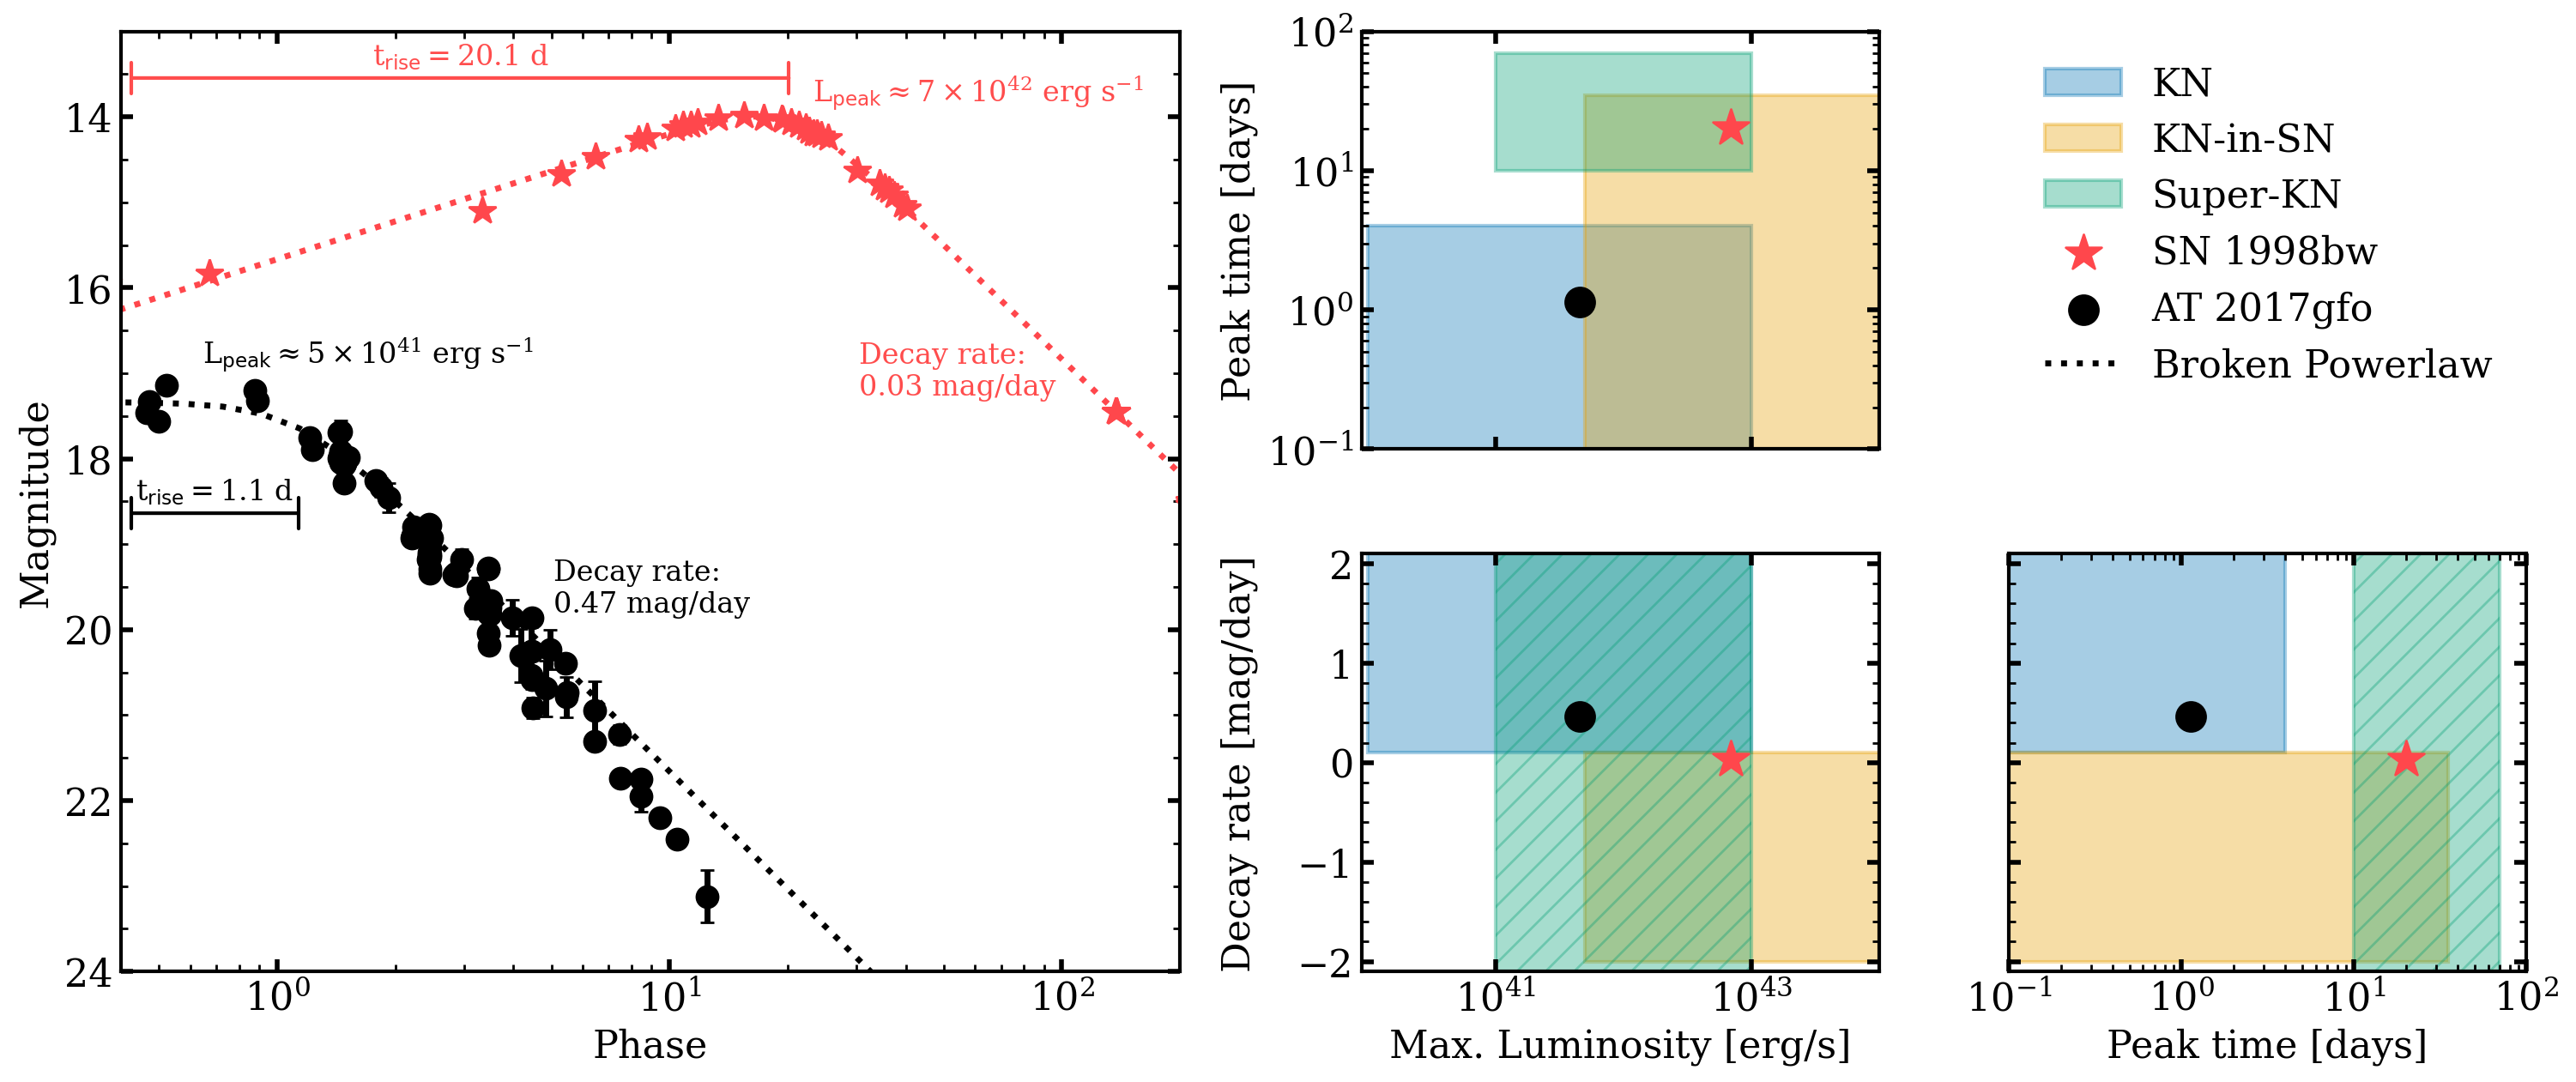

In [110]:
fig = plt.figure(figsize=(15, 6.5))
sf_lc, sf_corner = fig.subfigures(1, 2, width_ratios=[1, 1.1])
ax_lc = sf_lc.subplots()                  # light curve panel
axes  = make_corner_axes(sf_corner, 3, space=0.25)    # 3x3 corner grid

# lightcurve fit plot
xlim = 0.4, 200

bw = add_98bw(ax_lc, overwrite=False)
bw = bw[(bw.phase >= xlim[0]) * (bw.phase <= xlim[1])]
gfo = add_17gfo(ax_lc)
gfo = gfo[(gfo.Phase >= xlim[0]) * (gfo.Phase <= 10)]

# fit with BPL
bw_fit = fit_bpl(bw.phase, bw.converted_flux, bw.converted_flux_err.fillna(0.1))
gfo_fit = fit_bpl(gfo.Phase, gfo.mag, gfo.e_mag)

x = np.logspace(-2, 2.8)
ax_lc.plot(x, bpl(x, *bw_fit), linestyle=":", color="#FF474C") #  1.5 , -6, 13.74508742, 20.13816429
ax_lc.plot(x, bpl(x, *gfo_fit), linestyle=":", color="k") # 4.32095478e-14, -5.5,  1.73370308e+01,  1.13131638e+00

# ax.set_yscale("log")
ax_lc.set_ylim(24, 13)
ax_lc.set_xlim(*xlim)
ax_lc.set_xscale("log")

ax_lc.set_xlabel("Phase")
ax_lc.set_ylabel("Magnitude")

# bw_fit, gfo_fit

PARAM_NAMES = ["lum_max", "peak_time", "decay_rate"]

names = list(MODELS_BY_NAME)
regions = [params_to_ranges(MODELS_BY_NAME[n]) for n in names]

corner_ranges(
    axes, regions,
    param_labels=[r"Max. Luminosity [erg/s]", "Peak time [days]", "Decay rate [mag/day]"],
    region_labels=names,
    log_params=(0,1),
    bounds = ((9e39, 1e44), (1e-1, 1e2), (-2.1, 2.1))                         
)
sf_corner.align_ylabels(axes[:, 0])

bw_params = unpack_popt(bw_fit, "R", d_bw, bw.phase, bw.converted_flux)
print(bw_params)

gfo_params = unpack_popt(gfo_fit, "r", d_gfo, gfo.Phase, gfo.mag)
print(gfo_params)

add_point(axes, bw_params,  color="#FF474C", label="SN 1998bw", size=250)
add_point(axes, gfo_params, color="k", marker="o", label="AT 2017gfo", size=150)
corner_legend(axes)

# add annotations
bw_lum, bw_tpk, bw_rate = bw_params
annotate_lc(
    ax_lc, bw_fit, bw_lum, bw_rate, 
    lum_offset=2, 
    lum_offset_x=10,
    ha="left",
    color="#ff4d4d", 
    fontsize=12,
    bar_offset=0.5,
    mags = bw.converted_flux.values,
    decay_offset=(-20,-80),
    decay_at=2
)

gfo_lum, gfo_tpk, gfo_rate = gfo_params
annotate_lc(
    ax_lc, gfo_fit, gfo_lum, gfo_rate, 
    color="k",
    ha="left",
    decay_at=4, 
    lum_offset=5, 
    fontsize=12,
    bar_offset=-1,
    mags = gfo.mag.values,
    lum_offset_x=-40
)